<a href="https://colab.research.google.com/github/bogdanych/ML-homeworks/blob/main/practical/HomeWork3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Домашнее задание 3. Кредитный скоринг

In [73]:
!pip install --upgrade kagglehub[pandas-datasets] imbalanced-learn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
%matplotlib inline

# Шаг 0. Описание задачи
Задача: бинарная классификация. По социально-демографическим и финансовым характеристикам заёмщика (возраст, доход, стаж, сумма кредита, процентная ставка, цель кредита, кредитный рейтинг и т.д.) нужно предсказать, вернёт ли клиент кредит (loan_status = 0) или допустит дефолт (loan_status = 1). Это классическая задача кредитного скоринга. Ошибка в сторону «пропустить дефолт» (False Negative) обычно дороже банку, чем ошибка «отказать хорошему клиенту», поэтому в оценке качества будем ориентироваться не только на Accuracy, но и на Recall и F1 по классу дефолта.

# Шаг 1. Считываем данные

In [74]:
file_path = "credit_risk_dataset.csv"
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "laotse/credit-risk-dataset",
    file_path
)

print("Размер данных:", df.shape)
display(df.head())
print("\nТипы данных и пропуски:")
df.info()

/tmp/ipykernel_1617/2828722669.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'credit-risk-dataset' dataset.
Размер данных: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,1,0.590,Y,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0,0.100,N,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,1,0.570,N,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,1,0.530,N,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,1,0.550,Y,4



Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


#Шаг 2. Разбиение на обучающую и тестовую выборки

In [75]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("\nДоли классов в train:")
print(y_train.value_counts(normalize=True).round(4))
print("\nДоли классов в test:")
print(y_test.value_counts(normalize=True).round(4))

Train: (26064, 11), Test: (6517, 11)

Доли классов в train:
loan_status
0   0.782
1   0.218
Name: proportion, dtype: float64

Доли классов в test:
loan_status
0   0.782
1   0.218
Name: proportion, dtype: float64


#Шаг 3. Визуализация и основные характеристики

Есть следующие признаки:

person_age - возраст заемщика

person_income - годовой доход

person_home_ownership - тип жилья (RENT, OWN, MORTGAGE, OTHER)

person_emp_length - стаж работы (сколько лет)

loan_intent - Цель кредита: PERSONAL, EDUCATION, MEDICAL, HOMEIMPROVEMENT, VENTURE, DEBTCONSOLIDATION

loan_grade - Кредитный рейтинг от A (низкий риск) до G (высокий риск)

loan_amnt - запрошенная сумма кредита

loan_int_rate - процентная ставка по кредиту

loan_percent_income - доля дохода, уходящая на выплату (отношение платежа к доходу)

cb_person_default_on_file - был ли у человека дефолт в прошлом

cb_person_cred_hist_length - длина кредитной истории (число лет)

loan_status - 0 — кредит не в дефолте (погашен / обслуживается), 1 — дефолт


Числовые признаки:       ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Категориальные признаки: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Описательные статистики числовых признаков (train):


,count,mean,std,min,25%,50%,75%,max
person_age,26064.000,27.703,6.327,20.000,23.000,26.000,30.000,144.000
person_income,26064.000,66043.498,63715.995,4000.000,38443.250,55000.000,79000.000,6000000.000
person_emp_length,25326.000,4.795,4.172,0.000,2.000,4.000,7.000,123.000
loan_amnt,26064.000,9569.114,6295.931,500.000,5000.000,8000.000,12000.000,35000.000
loan_int_rate,23563.000,11.016,3.235,5.420,7.900,10.990,13.470,22.480
loan_percent_income,26064.000,0.170,0.107,0.000,0.090,0.150,0.230,0.830
cb_person_cred_hist_length,26064.000,5.787,4.035,2.000,3.000,4.000,8.000,30.000


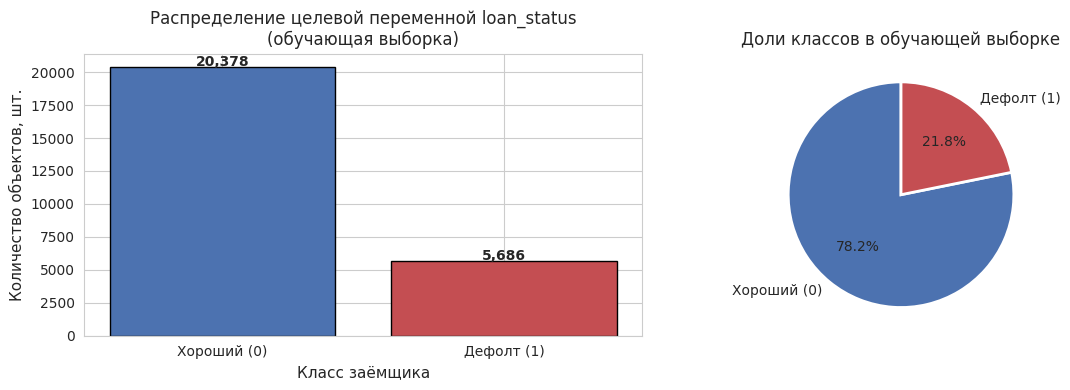

Интерпретация: класс дефолтов миноритарный (~22%). Accuracy в одиночку будет обманчива — основная метрика Recall и F1 по классу 1.



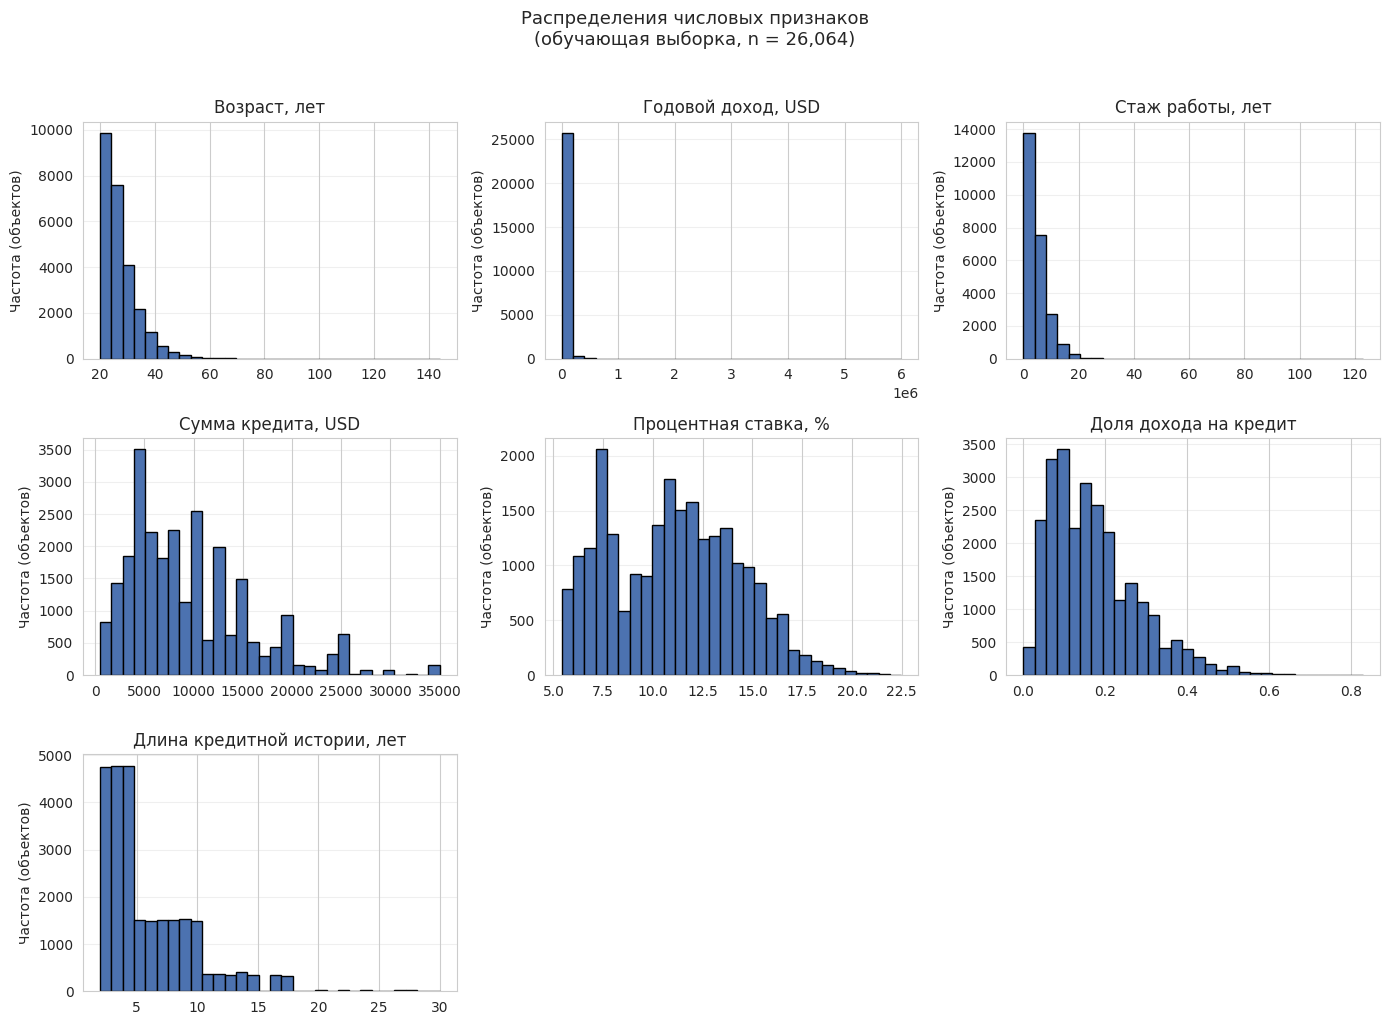

Интерпретация: у person_income, loan_amnt и person_emp_length — длинные правые хвосты
(видно на гистограммах): основная масса клиентов сосредоточена в относительно узком
диапазоне, но есть клиенты с экстремально большими значениями. Это указывает на
необходимость обработки выбросов (Шаг 4) и обязательной нормализации (Шаг 7).



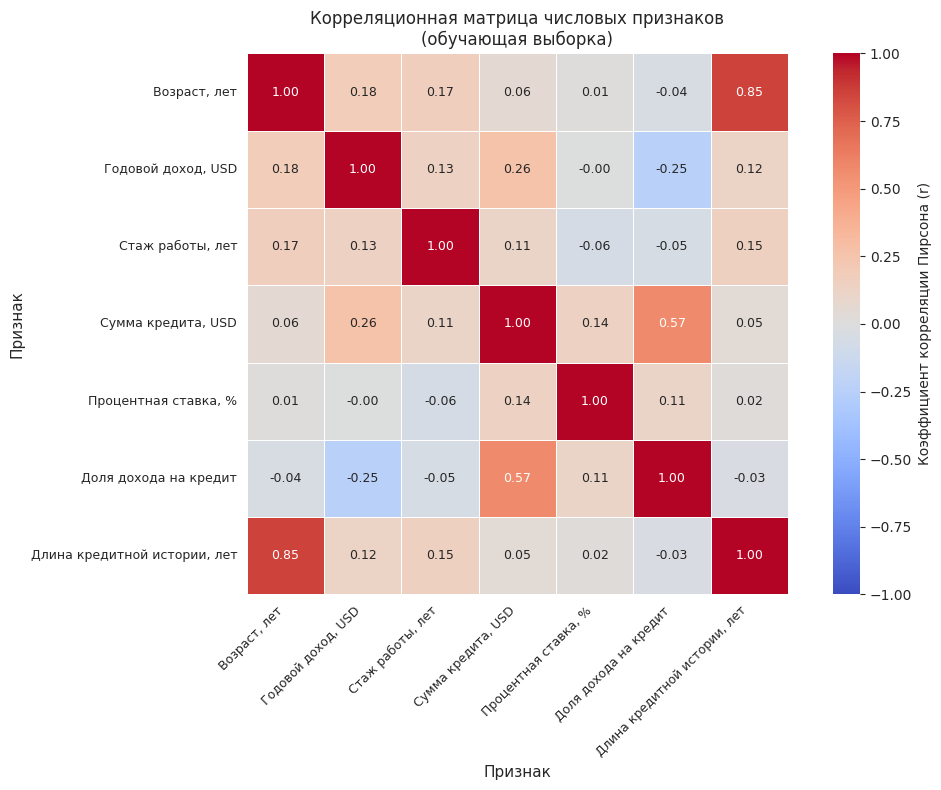

Интерпретация:
  • person_age ↔ cb_person_cred_hist_length: r ≈ 0.86 — очень сильная положительная
    связь. Логично: чем старше человек, тем длиннее его кредитная история. Признаки
    дублируют друг друга → один из них можно удалить (Шаг 12).
  • loan_amnt ↔ loan_percent_income: r ≈ 0.57 — умеренная положительная связь.
  • Остальные пары дают |r| < 0.5 — информация в них в значительной степени разная.
  • Отрицательных корреляций почти нет — признаки описывают разные аспекты
    профиля заёмщика.



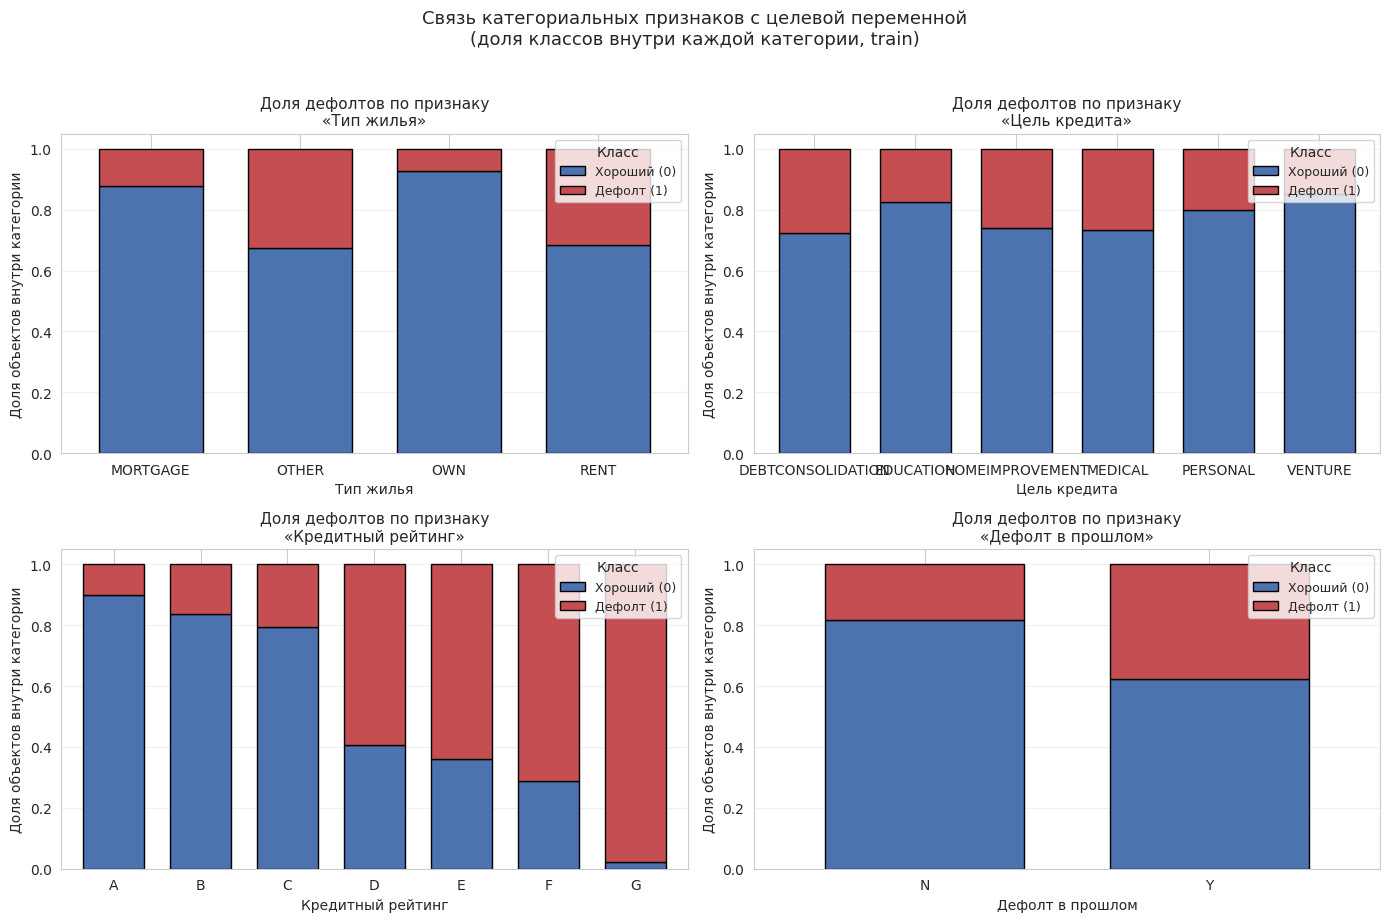

Интерпретация:
  • loan_grade — самый сильный предиктор: доля дефолтов растёт от A (низкий риск)
    к G (высокий риск). Монотонная зависимость.
  • person_home_ownership: у категорий RENT и OTHER доля дефолтов выше, чем
    у OWN и MORTGAGE — аренда жилья связана с меньшей финансовой устойчивостью.
  • loan_intent: DEBTCONSOLIDATION (рефинансирование) и MEDICAL дают повышенную
    долю дефолтов, EDUCATION и VENTURE — пониженную.
  • cb_person_default_on_file: если в прошлом был дефолт (Y), доля дефолтов
    заметно выше — исторический сигнал работает.



In [76]:
# ============================================================
# Шаг 3. Визуализация и основные характеристики
# ============================================================

# --- Словарь русских названий признаков для подписей осей ---
feature_ru = {
    'person_age':               'Возраст, лет',
    'person_income':            'Годовой доход, USD',
    'person_emp_length':        'Стаж работы, лет',
    'loan_amnt':                'Сумма кредита, USD',
    'loan_int_rate':            'Процентная ставка, %',
    'loan_percent_income':      'Доля дохода на кредит',
    'cb_person_cred_hist_length': 'Длина кредитной истории, лет',
    'person_home_ownership':    'Тип жилья',
    'loan_intent':              'Цель кредита',
    'loan_grade':               'Кредитный рейтинг',
    'cb_person_default_on_file':'Дефолт в прошлом',
}

# --- Определяем типы признаков ---
numeric_cols     = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Числовые признаки:      ", numeric_cols)
print("Категориальные признаки:", categorical_cols)

print("\nОписательные статистики числовых признаков (train):")
display(X_train[numeric_cols].describe().T)

# ============================================================
# Распределение целевой переменной
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# --- Столбчатая диаграмма ---
counts = y_train.value_counts().sort_index()
ax[0].bar(['Хороший (0)', 'Дефолт (1)'], counts.values, color=['#4c72b0', '#c44e52'],
          edgecolor='black')
ax[0].set_title('Распределение целевой переменной loan_status\n(обучающая выборка)',
                fontsize=12)
ax[0].set_xlabel('Класс заёмщика', fontsize=11)
ax[0].set_ylabel('Количество объектов, шт.', fontsize=11)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 50, f'{v:,}', ha='center', fontsize=10, fontweight='bold')

# --- Круговая диаграмма ---
ax[1].pie(counts.values, labels=['Хороший (0)', 'Дефолт (1)'],
          autopct='%1.1f%%', colors=['#4c72b0', '#c44e52'],
          startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax[1].set_title('Доли классов в обучающей выборке', fontsize=12)

plt.tight_layout(); plt.show()

print("Интерпретация: класс дефолтов миноритарный (~22%). "
      "Accuracy в одиночку будет обманчива — основная метрика Recall и F1 по классу 1.\n")


# Гистограммы числовых признаков

X_train_ru = X_train[numeric_cols].rename(columns=feature_ru)

axes = X_train_ru.hist(figsize=(14, 10), bins=30, edgecolor='black', color='#4c72b0')
for ax in axes.flat:
    ax.set_ylabel('Частота (объектов)')
    ax.grid(axis='y', alpha=0.3)
plt.suptitle('Распределения числовых признаков\n(обучающая выборка, n = '
             f'{len(X_train):,})', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print("Интерпретация: у person_income, loan_amnt и person_emp_length — длинные правые хвосты\n"
      "(видно на гистограммах): основная масса клиентов сосредоточена в относительно узком\n"
      "диапазоне, но есть клиенты с экстремально большими значениями. Это указывает на\n"
      "необходимость обработки выбросов (Шаг 4) и обязательной нормализации (Шаг 7).\n")


# 3.4. Корреляционная матрица (только числовые)

plt.figure(figsize=(11, 8))
corr = X_train[numeric_cols].corr()
corr.index   = [feature_ru.get(c, c) for c in corr.index]
corr.columns = [feature_ru.get(c, c) for c in corr.columns]

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={'label': 'Коэффициент корреляции Пирсона (r)'},
            annot_kws={'size': 9})
plt.title('Корреляционная матрица числовых признаков\n(обучающая выборка)',
          fontsize=12)
plt.xlabel('Признак', fontsize=11)
plt.ylabel('Признак', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout(); plt.show()

print("Интерпретация:\n"
      "  • person_age ↔ cb_person_cred_hist_length: r ≈ 0.86 — очень сильная положительная\n"
      "    связь. Логично: чем старше человек, тем длиннее его кредитная история. Признаки\n"
      "    дублируют друг друга → один из них можно удалить (Шаг 12).\n"
      "  • loan_amnt ↔ loan_percent_income: r ≈ 0.57 — умеренная положительная связь.\n"
      "  • Остальные пары дают |r| < 0.5 — информация в них в значительной степени разная.\n"
      "  • Отрицательных корреляций почти нет — признаки описывают разные аспекты\n"
      "    профиля заёмщика.\n")


# Категориальные признаки
n_show = min(4, len(categorical_cols))
if n_show == 0:
    print("Категориальных признаков нет — раздел пропускаем.")
else:
    n_rows = (n_show + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4.5 * n_rows), squeeze=False)

    for i, col in enumerate(categorical_cols[:n_show]):
        ax = axes.flat[i]
        ct = pd.crosstab(X_train[col], y_train, normalize='index').sort_index()
        ct.columns = ['Хороший (0)', 'Дефолт (1)']
        ct.plot(kind='bar', stacked=True, ax=ax,
                color=['#4c72b0', '#c44e52'], edgecolor='black', width=0.7)
        ax.set_title(f'Доля дефолтов по признаку\n«{feature_ru.get(col, col)}»',
                     fontsize=11)
        ax.set_xlabel(feature_ru.get(col, col), fontsize=10)
        ax.set_ylabel('Доля объектов внутри категории', fontsize=10)
        ax.legend(title='Класс', loc='upper right', fontsize=9)
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis='x', rotation=0)
        ax.grid(axis='y', alpha=0.3)

    for j in range(n_show, n_rows * 2):
        axes.flat[j].set_visible(False)

    plt.suptitle('Связь категориальных признаков с целевой переменной\n'
                 '(доля классов внутри каждой категории, train)',
                 fontsize=13, y=1.02)
    plt.tight_layout(); plt.show()

    print("Интерпретация:\n"
          "  • loan_grade — самый сильный предиктор: доля дефолтов растёт от A (низкий риск)\n"
          "    к G (высокий риск). Монотонная зависимость.\n"
          "  • person_home_ownership: у категорий RENT и OTHER доля дефолтов выше, чем\n"
          "    у OWN и MORTGAGE — аренда жилья связана с меньшей финансовой устойчивостью.\n"
          "  • loan_intent: DEBTCONSOLIDATION (рефинансирование) и MEDICAL дают повышенную\n"
          "    долю дефолтов, EDUCATION и VENTURE — пониженную.\n"
          "  • cb_person_default_on_file: если в прошлом был дефолт (Y), доля дефолтов\n"
          "    заметно выше — исторический сигнал работает.\n")

#Шаг 4. Обработка выбросов

В прошлом шаге можно было заметить неадекватные выбросы, вроде 140 лет или стаж работы 120 лет, что явно является ошибкой.

В качестве метода обнаружения выбросов используется правило межквартильного размаха (IQR): значения ниже
Q
1
−
1.5
⋅
IQR
Q
1
​
 −1.5⋅IQR и выше
Q
3
+
1.5
⋅
IQR
Q
3
​
 +1.5⋅IQR считаются выбросами. Это непараметрический метод, он не требует предположения о нормальности распределения — что важно, так как распределения в датасете скошены.

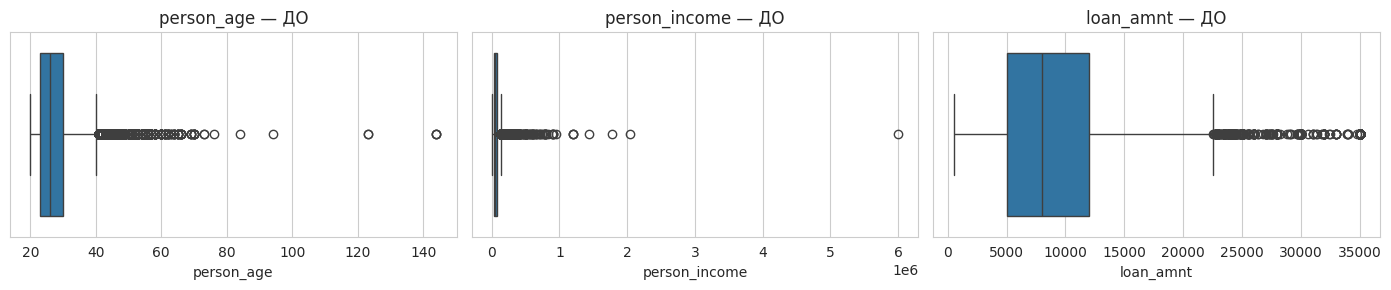

person_age: [12.5, 40.5]
person_income: [-22391.9, 139835.1]
person_emp_length: [-5.5, 14.5]
loan_amnt: [-5500.0, 22500.0]


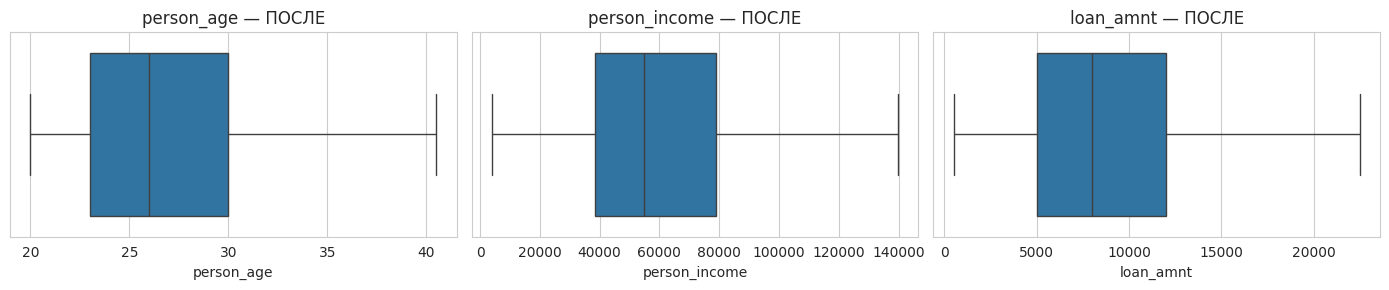

In [77]:
def cap_outliers_iqr(train, test, cols):
    """Цензурирование по IQR: границы считаем по train, применяем к обоим."""
    tr, te = train.copy(), test.copy()
    bounds = {}
    for col in cols:
        q1, q3 = tr[col].quantile(0.25), tr[col].quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        bounds[col] = (lo, hi)
        tr[col] = tr[col].clip(lo, hi)
        te[col] = te[col].clip(lo, hi)
    return tr, te, bounds

# Боксплоты ДО
plt.figure(figsize=(14, 3))
for i, col in enumerate(['person_age', 'person_income', 'loan_amnt'], 1):
    plt.subplot(1, 3, i); sns.boxplot(x=X_train[col]); plt.title(f'{col} — ДО')
plt.tight_layout(); plt.show()

X_train, X_test, bounds = cap_outliers_iqr(
    X_train, X_test,
    cols=['person_age', 'person_income', 'person_emp_length', 'loan_amnt']
)
for col, (lo, hi) in bounds.items():
    print(f"{col}: [{lo:.1f}, {hi:.1f}]")

# Боксплоты ПОСЛЕ
plt.figure(figsize=(14, 3))
for i, col in enumerate(['person_age', 'person_income', 'loan_amnt'], 1):
    plt.subplot(1, 3, i); sns.boxplot(x=X_train[col]); plt.title(f'{col} — ПОСЛЕ')
plt.tight_layout(); plt.show()

# Шаг 5. Обработка пропущенных значений
В датасете пропуски сосредоточены всего в двух столбцах — person_emp_length (стаж работы) и loan_int_rate (процентная ставка). Оставлять их нельзя: KNN и большинство классификаторов не работают с NaN, а удаление строк потеряло бы ~13% данных и усилило бы дисбаланс классов. Поэтому заполняем пропуски медианой: распределения этих признаков скошены вправо, и медиана, в отличие от среднего, устойчива к выбросам и даёт «типичное» значение. Медиана считается только на X_train и применяется к обоим наборам — иначе была бы утечка данных из теста.

In [79]:
miss_train = X_train.isnull().sum()
miss_test  = X_test.isnull().sum()
print("Пропуски в train:\n", miss_train[miss_train > 0])
print("Пропуски в test:\n",  miss_test[miss_test > 0])

# Медиана — считается на train, применяется к обоим наборам
for col in X_train.columns:
    if X_train[col].isnull().any():
        if X_train[col].dtype in ['float64', 'int64']:
            fill = X_train[col].median()
            X_train[col] = X_train[col].fillna(fill)
            X_test[col]  = X_test[col].fillna(fill)
            print(f"  {col}: заполнено медианой = {fill:.2f}")
        else:
            fill = X_train[col].mode()[0]
            X_train[col] = X_train[col].fillna(fill)
            X_test[col]  = X_test[col].fillna(fill)
            print(f"  {col}: заполнено модой = {fill}")

assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0
print("\nПропусков больше нет.")

Пропуски в train:
 person_emp_length     738
loan_int_rate        2501
dtype: int64
Пропуски в test:
 person_emp_length    157
loan_int_rate        615
dtype: int64
  person_emp_length: заполнено медианой = 4.00
  loan_int_rate: заполнено медианой = 10.99

Пропусков больше нет.


#Шаг 6. Обработка категориальных признаков

Четыре категориальных признака (person_home_ownership, loan_intent, loan_grade, cb_person_default_on_file) переводим в числовой вид через One-Hot Encoding — каждое значение категории становится отдельным бинарным столбцом, что корректно для признаков без естественного порядка и не навязывает модели ложную линейность. Кодировщик обучается только на X_train, а handle_unknown='ignore' защищает от незнакомых категорий в тесте.

# Шаг 7. Нормализация

Нормализация обязательна, потому что KNN основан на евклидовом расстоянии, а признаки имеют несопоставимые масштабы (person_income — десятки тысяч, person_age — десятки): без масштабирования расстояние определялось бы почти только доходом. Применяем StandardScaler только к числовым признакам (One-Hot-столбцы уже в [0, 1]).



In [80]:
# Поскольку OneHotEncoder выдаёт 0/1 (уже "числовые" значения), его ставим рядом со StandardScaler
# в ColumnTransformer — так масштаб корректно применяется только к числовым признакам.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),                    # шаг 7: нормализация
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False), categorical_cols)  # шаг 6: кодирование
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)     # fit — только на train!
X_test_processed  = preprocessor.transform(X_test)          # transform — на test

print("Размер после препроцессинга:")
print(f"  train: {X_train_processed.shape}")
print(f"  test:  {X_test_processed.shape}")

# Посмотреть имена получившихся признаков
feature_names = preprocessor.get_feature_names_out()
print(f"\nВсего признаков: {len(feature_names)}")
print("Примеры:", list(feature_names[:8]))

Размер после препроцессинга:
  train: (26064, 26)
  test:  (6517, 26)

Всего признаков: 26
Примеры: ['num__person_age', 'num__person_income', 'num__person_emp_length', 'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income', 'num__cb_person_cred_hist_length', 'cat__person_home_ownership_MORTGAGE']


#Шаг 8. Классификатор K-ближайших соседей
Выбираем K-ближайших соседей (KNN) — простой и интерпретируемый метод, который  не требует обучения коэффициентов, а значит, по построению устойчив к мультиколлинеарности. KNN хорошо работает как baseline для табличных данных с числовыми и бинарными признаками после масштабирования. В качестве базовой модели запускаем его с k=5, а оптимальное k подберём на Шаге 9.

In [81]:
# Базовый запуск для оценки
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_processed, y_train)
y_train_pred = knn_base.predict(X_train_processed)
y_test_pred  = knn_base.predict(X_test_processed)

train_err = 1 - accuracy_score(y_train, y_train_pred)
test_err  = 1 - accuracy_score(y_test,  y_test_pred)
print(f"Ошибка на train: {train_err:.4f}")
print(f"Ошибка на test:  {test_err:.4f}")

Ошибка на train: 0.0821
Ошибка на test:  0.1123


#Шаг 9. Ошибки, матрицы рассогласования, подбор k

=== KNN (k=5) ===


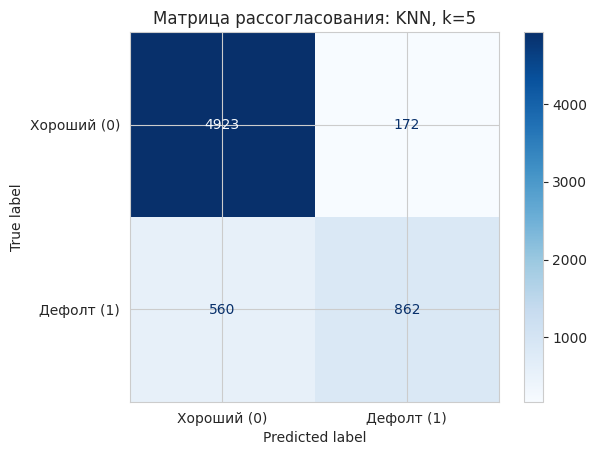

              precision    recall  f1-score   support

 Хороший (0)       0.90      0.97      0.93      5095
  Дефолт (1)       0.83      0.61      0.70      1422

    accuracy                           0.89      6517
   macro avg       0.87      0.79      0.82      6517
weighted avg       0.88      0.89      0.88      6517


Лучшее k = 12
Лучший F1 (CV, среднее) = 0.7192


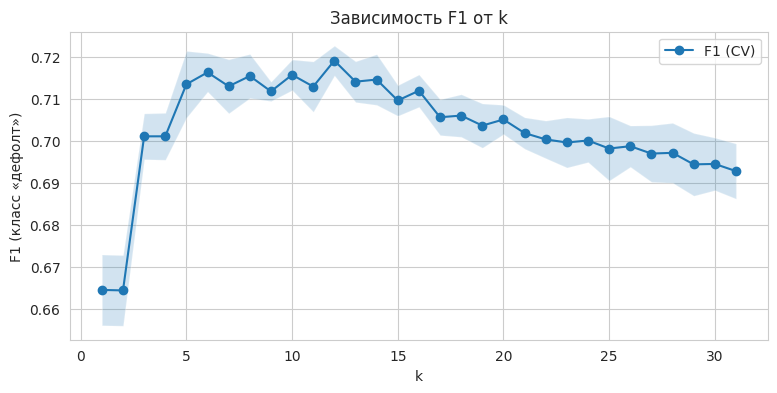


=== KNN (k=12) на тесте ===
Ошибка на train: 0.0000
Ошибка на test:  0.1053


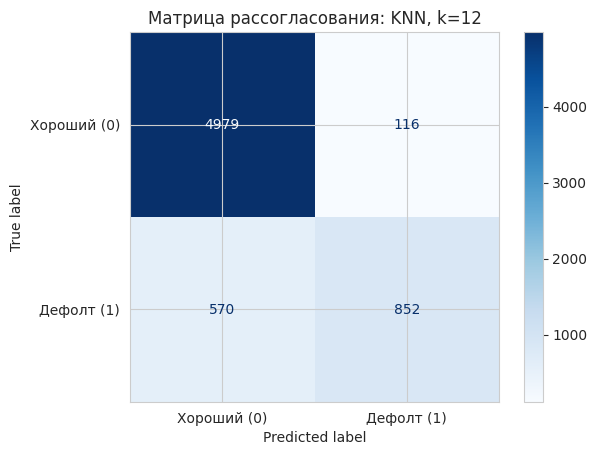

              precision    recall  f1-score   support

 Хороший (0)       0.90      0.98      0.94      5095
  Дефолт (1)       0.88      0.60      0.71      1422

    accuracy                           0.89      6517
   macro avg       0.89      0.79      0.82      6517
weighted avg       0.89      0.89      0.89      6517



In [83]:
# --- 9.1. Матрица рассогласования для базовой модели ---
print("=== KNN (k=5) ===")
cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=['Хороший (0)', 'Дефолт (1)']).plot(cmap='Blues')
plt.title('Матрица рассогласования: KNN, k=5')
plt.show()
print(classification_report(y_test, y_test_pred, target_names=['Хороший (0)', 'Дефолт (1)']))

# --- 9.2. Подбор оптимального k через 5-кратную CV по F1-мере ---
pipe = Pipeline([
    ('prep', preprocessor),
    ('clf',  KNeighborsClassifier(weights='distance'))
])

param_grid = {'clf__n_neighbors': list(range(1, 32))}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)   # передаём СЫРОЙ X_train — пайплайн сделает препроцессинг внутри CV

print(f"\nЛучшее k = {grid.best_params_['clf__n_neighbors']}")
print(f"Лучший F1 (CV, среднее) = {grid.best_score_:.4f}")

# --- 9.3. Кривая F1(CV) vs k ---
cv_results = pd.DataFrame(grid.cv_results_)
plt.figure(figsize=(9, 4))
plt.plot(cv_results['param_clf__n_neighbors'], cv_results['mean_test_score'],
         marker='o', label='F1 (CV)')
plt.fill_between(cv_results['param_clf__n_neighbors'],
                 cv_results['mean_test_score'] - cv_results['std_test_score'],
                 cv_results['mean_test_score'] + cv_results['std_test_score'],
                 alpha=0.2)
plt.xlabel('k'); plt.ylabel('F1 (класс «дефолт»)')
plt.title('Зависимость F1 от k'); plt.legend(); plt.grid(True); plt.show()

# --- 9.4. Финальная оценка модели с лучшим k на тесте ---
best_knn = grid.best_estimator_
y_test_pred_best = best_knn.predict(X_test)
y_train_pred_best = best_knn.predict(X_train)

print(f"\n=== KNN (k={grid.best_params_['clf__n_neighbors']}) на тесте ===")
print(f"Ошибка на train: {1 - accuracy_score(y_train, y_train_pred_best):.4f}")
print(f"Ошибка на test:  {1 - accuracy_score(y_test,  y_test_pred_best):.4f}")
cm_best = confusion_matrix(y_test, y_test_pred_best)
ConfusionMatrixDisplay(cm_best, display_labels=['Хороший (0)', 'Дефолт (1)']).plot(cmap='Blues')
plt.title(f'Матрица рассогласования: KNN, k={grid.best_params_["clf__n_neighbors"]}')
plt.show()
print(classification_report(y_test, y_test_pred_best, target_names=['Хороший (0)', 'Дефолт (1)']))

# Комментарии по шагу 9

Особенность задачи в том, что пропустить дефолт (Type II, FN) дороже банку, чем отказать хорошему клиенту (Type I, FP). Стандартный KNN с мажоритарным голосованием не различает стоимость ошибок, но это можно частично компенсировать весами соседей, сдвигом порога или SMOTE (Шаг 11).

В наших результатах ошибок Type II в 4–5 раз больше, чем Type I: класс дефолтов миноритарный, и модель смещена в сторону большинства — класса «хороший».

Кросс-валидация выбрала k = 12 как компромисс между переобучением (малые k) и недообучением (большие k). При этом, стоит заметить, что при нечетных k результат хуже. Стоит полагать - это связано с пограничными ситуациями, когда среди k соседей одинаковое количество представителей обоих классов. В этом случае делается выбор по принципу weights='distance' (ближние соседи получают больший вес).


#Шаг 10. Сравнение с другими классификаторами

Обучаем логистическую регрессию и случайный лес с class_weight='balanced' и сравниваем их с лучшим KNN по Accuracy, Precision, Recall и F1 по классу «дефолт». Логистическая регрессия — интерпретируемый линейный baseline, коэффициенты которого можно объяснить бизнесу; случайный лес — мощный нелинейный ансамбль, обычно дающий лучший Recall по миноритарному классу. Все три модели обучаются в одном Pipeline с тем же препроцессором, чтобы сравнение было честным, а не из-за разных способов обработки данных.



In [85]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42,
                                              class_weight='balanced'),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=42,
                                                  class_weight='balanced', n_jobs=-1),
    'KNN (best k)':        KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'], weights='distance')
}

results = {}
for name, model in models.items():
    p = Pipeline([('prep', preprocessor), ('clf', model)])
    p.fit(X_train, y_train)
    pred = p.predict(X_test)
    results[name] = {
        'Accuracy':        accuracy_score(y_test, pred),
        'Precision (1)':   precision_score(y_test, pred, pos_label=1),
        'Recall (1)':      recall_score(y_test, pred, pos_label=1),
        'F1 (1)':          f1_score(y_test, pred, pos_label=1),
    }

summary = pd.DataFrame(results).T.round(4)
print("\n=== Сводная таблица (тест) ===")
display(summary)


=== Сводная таблица (тест) ===


,Accuracy,Precision (1),Recall (1),F1 (1)
Logistic Regression,0.815,0.553,0.783,0.648
Random Forest,0.934,0.977,0.714,0.825
KNN (best k),0.895,0.880,0.599,0.713


Сравнение трёх моделей показало, что Random Forest лидирует по F1 (0.825) и Precision (0.977), но пропускает ~29% дефолтов. Logistic Regression даёт максимальный Recall (0.783), то есть лучше всех ловит «плохих» клиентов — ценой большего числа ложных отказов (Precision 0.553). KNN занимает промежуточное положение с Precision 0.880 и Recall 0.599. Итоговый выбор зависит от стоимости ошибок: если банк готов на лишние отказы ради минимизации потерь от невозвратов, оптимальна логистическая регрессия; если важнее сбалансированный результат — Random Forest.

#Шаг 11. Борьба с несбалансированностью (SMOTE)

Класс дефолтов составляет ~22%, и стандартный KNN с мажоритарным голосованием смещён в сторону «хороших» заёмщиков — именно поэтому на Шагах 9 и 10 Recall по дефолтам был низким. Применяем SMOTE (Synthetic Minority Over-sampling Technique): он генерирует синтетические объекты миноритарного класса путём интерполяции между реальными «соседями-дефолтами», в отличие от простого дублирования не создавая копий и снижая риск переобучения

In [86]:
# Важно: SMOTE применяем ТОЛЬКО к train (после препроцессинга) — иначе утечка.
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_processed, y_train)

print("До SMOTE:", np.bincount(y_train))
print("После SMOTE:", np.bincount(y_train_sm))

knn_sm = KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'])
knn_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = knn_sm.predict(X_test_processed)

print("\n=== KNN после SMOTE (тест) ===")
print(classification_report(y_test, y_pred_sm, target_names=['Хороший (0)', 'Дефолт (1)']))

# Сравнение с моделью без SMOTE
print("\nСравнение (только по классу «дефолт»):")
print(f"{'':20s} {'F1':>8s} {'Recall':>8s}")
print(f"{'Без SMOTE':20s} {f1_score(y_test, y_test_pred_best, pos_label=1):8.4f} "
      f"{recall_score(y_test, y_test_pred_best, pos_label=1):8.4f}")
print(f"{'Со SMOTE':20s} {f1_score(y_test, y_pred_sm, pos_label=1):8.4f} "
      f"{recall_score(y_test, y_pred_sm, pos_label=1):8.4f}")

До SMOTE: [20378  5686]
После SMOTE: [20378 20378]

=== KNN после SMOTE (тест) ===
              precision    recall  f1-score   support

 Хороший (0)       0.93      0.85      0.89      5095
  Дефолт (1)       0.59      0.77      0.67      1422

    accuracy                           0.83      6517
   macro avg       0.76      0.81      0.78      6517
weighted avg       0.86      0.83      0.84      6517


Сравнение (только по классу «дефолт»):
                           F1   Recall
Без SMOTE              0.7130   0.5992
Со SMOTE               0.6687   0.7665


Что улучшилось: Recall вырос с 0.599 → 0.767 (+17 п.п.) — модель стала ловить почти 77% реальных дефолтов вместо 60%. Для банка это прямой выигрыш: меньше пропущенных «плохих» клиентов.

Что ухудшилось: F1 упал с 0.713 → 0.669. Это может показаться парадоксальным — ведь Recall вырос. Причина в том, что Precision обвалился. То есть модель теперь обозначает гораздо больше клиентов как дефолтных, и значительная часть этих тревог — ложные (FP).

Для кредитного скоринга Recall по классу дефолт обычно важнее Precision — лучше отказать нескольким хорошим, чем выдать кредит одному дефолтнику.


# Шаг 12. Исключение коррелированных переменных

In [87]:
# Считаем корреляции только на исходных числовых признаках train
corr_abs = X_train[numeric_cols].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

threshold = 0.85
pairs = upper.stack().loc[lambda s: s > threshold].sort_values(ascending=False)
print(f"Пары с |r| > {threshold}:")
print(pairs.to_string() if len(pairs) else "  (нет)")

to_drop = [c for c in upper.columns if any(upper[c] > threshold)]
print(f"\nПризнаки к удалению: {to_drop}")

# Модель ПОСЛЕ удаления
if to_drop:
    numeric_reduced = [c for c in numeric_cols if c not in to_drop]
    prep_red = ColumnTransformer([
        ('num', StandardScaler(), numeric_reduced),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])
    X_train_red = prep_red.fit_transform(X_train)
    X_test_red  = prep_red.transform(X_test)

    knn_red = KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'])
    knn_red.fit(X_train_red, y_train)
    y_pred_red = knn_red.predict(X_test_red)

    comparison = pd.DataFrame({
        'Модель':          ['KNN (все признаки)', 'KNN (без коррелированных)'],
        'Accuracy':        [accuracy_score(y_test, y_test_pred_best),
                            accuracy_score(y_test, y_pred_red)],
        'F1 (дефолт)':     [f1_score(y_test, y_test_pred_best, pos_label=1),
                            f1_score(y_test, y_pred_red, pos_label=1)],
        'Recall (дефолт)': [recall_score(y_test, y_test_pred_best, pos_label=1),
                            recall_score(y_test, y_pred_red, pos_label=1)],
    }).set_index('Модель')
    display(comparison.round(4))
else:
    print("Порог не превышен — удалять нечего.")

Пары с |r| > 0.85:
person_age  cb_person_cred_hist_length   0.858

Признаки к удалению: ['cb_person_cred_hist_length']


,Accuracy,F1 (дефолт),Recall (дефолт)
Модель,,,
KNN (все признаки),0.895,0.713,0.599
KNN (без коррелированных),0.896,0.708,0.577


Как видим, лучше не стало, поскольку для KNN линейная зависимость не имеет значения.

Однако отбор признаков всё же полезен: он снижает размерность, ускоряет расчёт расстояний (меньше «проклятие размерности») и упрощает интерпретацию модели. Таким образом, исключение коррелированных переменных в нашем случае — это вопрос эффективности и чистоты данных, а не качества предсказания.



# Шаг 13. Общие выводы

В кредитном скоринге оптимизация одной метрики (Accuracy или F1) некорректна: задача по своей природе асимметрична по стоимости ошибок. Правильный подход — выбрать модель по бизнес-критерию (например, максимизировать Recall при Precision ≥ 0.7), а затем тонко настроить порог классификации или веса классов. KNN оказался хорошим baseline и наглядной демонстрацией важности нормализации, но для продакшена логичнее ансамбли (RF) или регуляризованная логистическая регрессия с class_weight='balanced'.

